# 07 – Out-of-course model: TabNet

**ML Project – Early Detection of Students at Risk of Dropout** · Week 3

Module owner: **Timéo Brajon** · Group **AALT** (DIA4): Léo Chen, Adam Gaabi, Timéo Brajon, Axel Warot

## Why TabNet
**Reference:** Arik, S. Ö. & Pfister, T. (2021). *TabNet: Attentive Interpretable Tabular Learning*. AAAI 2021.

- Deep learning model designed for **tabular data**, outside the scope of the course.
- At each decision step, an **attentive transformer** selects a sparse subset of features (sparsemax mask); a feature transformer processes them; the outputs of all steps are summed.
- The masks give a **built-in feature importance**: useful to explain the risk factors to the school.
- The paper reports results close to or better than gradient boosting on several tabular benchmarks.

**Critical point:** later benchmarks (Grinsztajn, Oyallon & Varoquaux, NeurIPS 2022) show that tree-based models still often beat deep models on medium-sized tabular data. With 3,539 training students, we expect TabNet to be **at most as good as boosting**: we test this claim on our data.

In [1]:
import sys,json,time,warnings
warnings.filterwarnings("ignore")
sys.path.insert(0,"../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import *
from evaluation import *
pd.set_option("display.width",160)
pd.set_option("display.max_columns",40)
tr=pd.read_csv("../data/processed/train.csv")
import torch
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from pytorch_tabnet.tab_model import TabNetClassifier
torch.manual_seed(SEED)
s="B_semester1"
X,y=split_xy(tr,s)
y=encode(y)

## Protocol
Same outer 5-fold as notebooks 05–06. In each outer training fold, 15% is kept as an **inner validation set**: it is used for early stopping and to choose between 3 configurations. The outer fold is only used for the final score. Classes are re-weighted (`weights=1`).

In [2]:
CONFIGS=[{"n_d":8,"n_a":8,"n_steps":3,"gamma":1.3},{"n_d":16,"n_a":16,"n_steps":4,"gamma":1.5},{"n_d":24,"n_a":24,"n_steps":5,"gamma":1.5}]
chosen=[]
def tabnet(X_tr,y_tr,X_va):
    Xf,Xv,yf,yv=train_test_split(X_tr,y_tr,test_size=0.15,stratify=y_tr,random_state=SEED)
    p=preprocessor(s).fit(Xf)
    f=lambda Z:p.transform(Z).astype(np.float32)
    best=None
    for i,c in enumerate(CONFIGS):
        m=TabNetClassifier(**c,lambda_sparse=1e-4,optimizer_params={"lr":2e-2},seed=SEED,verbose=0)
        m.fit(f(Xf),yf,eval_set=[(f(Xv),yv)],eval_metric=["balanced_accuracy"],max_epochs=200,patience=25,batch_size=256,virtual_batch_size=64,weights=1)
        if best is None or m.best_cost>best[0]:best=(m.best_cost,i,m)
    chosen.append(best[1])
    pr=best[2].predict_proba(f(X_va))
    return pr.argmax(1),pr
t=time.perf_counter()
res=run_folds(tabnet,X,y,"TabNet",s)
print(f"TabNet: {time.perf_counter()-t:.0f} s, configuration chosen per fold: {chosen}")


Early stopping occurred at epoch 60 with best_epoch = 35 and best_val_0_balanced_accuracy = 0.63258



Early stopping occurred at epoch 108 with best_epoch = 83 and best_val_0_balanced_accuracy = 0.64678



Early stopping occurred at epoch 56 with best_epoch = 31 and best_val_0_balanced_accuracy = 0.64521



Early stopping occurred at epoch 71 with best_epoch = 46 and best_val_0_balanced_accuracy = 0.67725



Early stopping occurred at epoch 103 with best_epoch = 78 and best_val_0_balanced_accuracy = 0.66034



Early stopping occurred at epoch 47 with best_epoch = 22 and best_val_0_balanced_accuracy = 0.64965


... (6 outputs left out)


Early stopping occurred at epoch 85 with best_epoch = 60 and best_val_0_balanced_accuracy = 0.70226



Early stopping occurred at epoch 56 with best_epoch = 31 and best_val_0_balanced_accuracy = 0.64986



Early stopping occurred at epoch 165 with best_epoch = 140 and best_val_0_balanced_accuracy = 0.6918


TabNet: 352 s, configuration chosen per fold: [1, 0, 1, 2, 0]


Reference neural network seen in class: a scikit-learn MLP (2 hidden layers, early stopping), same folds.

In [3]:
mlp=Pipeline([("prep",preprocessor(s)),("clf",MLPClassifier(hidden_layer_sizes=(64,32),alpha=1e-3,early_stopping=True,max_iter=500,random_state=SEED))])
res=pd.concat([res,run_folds(sk(mlp),X,y,"MLP",s)])
res.to_csv("../results/w3_07_tabnet_folds.csv",index=False)
prev=pd.read_csv("../results/w3_05_boosting_folds.csv").query("model in ['Baseline LogReg','LightGBM']")
summary(pd.concat([prev,res])).round(3)

macro_f1  macro_f1_std  bal_acc  dropout_recall  enrolled_f1  roc_auc_ovr
scenario    model                                                                                     
B_semester1 LightGBM            0.702         0.025    0.706           0.718        0.513        0.876
            Baseline LogReg     0.684         0.022    0.692           0.699        0.488        0.863
            MLP                 0.664         0.032    0.658           0.740        0.397        0.866
            TabNet              0.626         0.023    0.634           0.649        0.408        0.817

## Feature importance (TabNet masks)
TabNet refitted on the whole training set (configuration chosen most often). Importances of the one-hot columns are summed back to the original feature.


Early stopping occurred at epoch 87 with best_epoch = 62 and best_val_0_balanced_accuracy = 0.68329


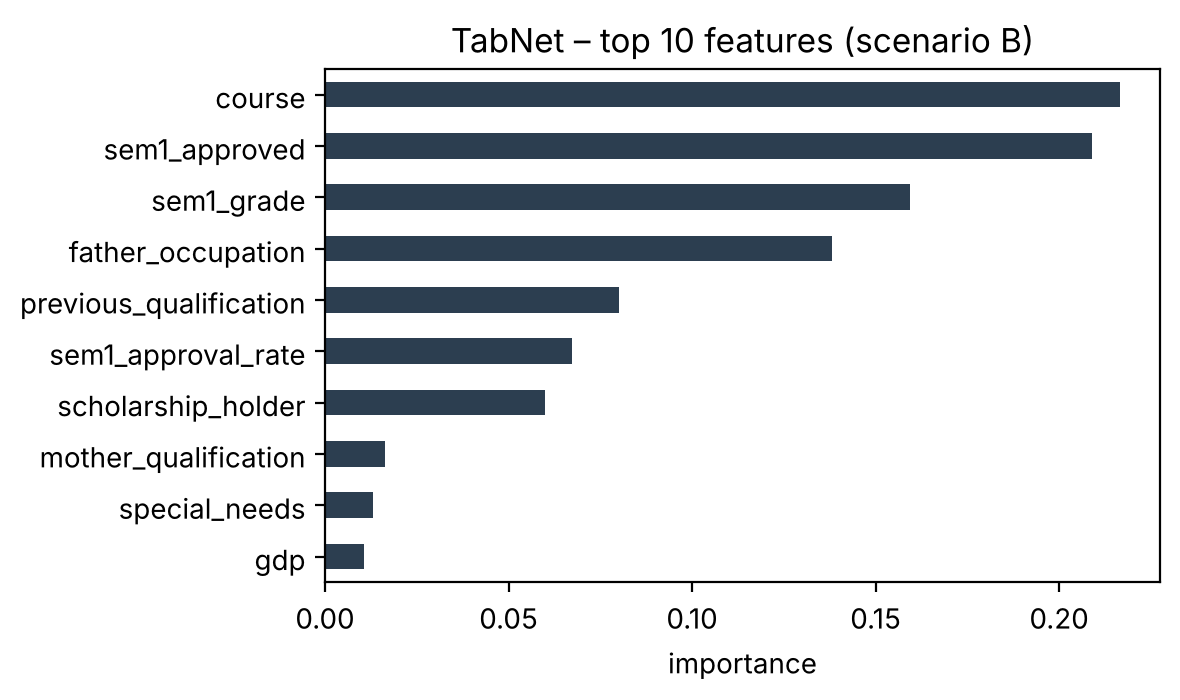

course                    0.217
sem1_approved             0.209
sem1_grade                0.159
father_occupation         0.138
previous_qualification    0.080
sem1_approval_rate        0.067
scholarship_holder        0.060
mother_qualification      0.016
special_needs             0.013
gdp                       0.011
dtype: float64

In [4]:
c=CONFIGS[max(set(chosen),key=chosen.count)]
Xf,Xv,yf,yv=train_test_split(X,y,test_size=0.15,stratify=y,random_state=SEED)
p=preprocessor(s).fit(Xf)
m=TabNetClassifier(**c,lambda_sparse=1e-4,optimizer_params={"lr":2e-2},seed=SEED,verbose=0)
m.fit(p.transform(Xf).astype(np.float32),yf,eval_set=[(p.transform(Xv).astype(np.float32),yv)],eval_metric=["balanced_accuracy"],max_epochs=200,patience=25,batch_size=256,virtual_batch_size=64,weights=1)
names=p.get_feature_names_out()
orig=[max((f for f in NOMINAL if n[5:].startswith(f+"_")),key=len) if n.startswith("nom__") else n.split("__",1)[1] for n in names]
imp=pd.Series(m.feature_importances_,index=orig).groupby(level=0).sum().sort_values(ascending=False)
ax=imp.head(10)[::-1].plot.barh(figsize=(6,3.6),color="#2c3e50");ax.set_title("TabNet – top 10 features (scenario B)");ax.set_xlabel("importance")
plt.tight_layout();plt.savefig("../report/figures/w3_tabnet_importance.png",dpi=150);plt.show()
imp.head(10).round(3)

- TabNet is the **weakest model** (macro-F1 0.626 vs. 0.684 for the baseline and 0.702 for LightGBM), below the simple MLP (0.664) too. This matches the critical literature: on ≈ 3,500 tabular rows, trees and even linear models remain stronger.
- It is much slower (352 s for 5 folds vs. ≈ 1 s for the baseline), and the configuration chosen changes from fold to fold (1, 0, 1, 2, 0).
- Its masks partly agree with the EDA (course, semester-1 approved units and grade at the top), but `father_occupation` is ranked 4th and `tuition_fees_up_to_date`, a very strong signal in the EDA, is not in the top 10: the masks of a single TabNet fit are not reliable enough to explain the risk factors. Week 4 will use permutation importance on the final model instead.